<a href="https://colab.research.google.com/github/Rhema5/CSA47-Deep-Learning/blob/main/DL_LAB_PROG_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=10000)

x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)

model = Sequential([
    Embedding(10000, 32),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=3,
          batch_size=64, validation_split=0.2)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy)

reviews = [
    "This product is excellent and very useful",
    "This product is very bad and disappointing"
]

word_index = imdb.get_word_index()

sequences = []
for review in reviews:
    words = review.lower().split()
    sequence = [word_index.get(word, 2) + 3 for word in words]
    sequences.append(sequence)

sequences = pad_sequences(sequences, maxlen=200)

predictions = model.predict(sequences)

for i, prediction in enumerate(predictions):
    sentiment = "Positive" if prediction[0] >= 0.5 else "Negative"
    print(reviews[i], ":", sentiment)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.6043 - loss: 0.6506 - val_accuracy: 0.6904 - val_loss: 0.5922
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.8152 - loss: 0.4136 - val_accuracy: 0.8200 - val_loss: 0.4060
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 53ms/step - accuracy: 0.9068 - loss: 0.2397 - val_accuracy: 0.8354 - val_loss: 0.3989
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8322 - loss: 0.4025
Test Accuracy: 0.8322399854660034
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step
This product is excellent and very useful : Positive
This product is very bad and disappointing : Negative


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

text = """deep learning is a part of machine learning.
neural networks are used in artificial intelligence.
recurrent neural networks process sequential data.
deep learning helps computers learn from data."""

chars = sorted(set(text))
char_to_index = {c: i for i, c in enumerate(chars)}
index_to_char = {i: c for i, c in enumerate(chars)}

sequence_length = 20

x = []
y = []

for i in range(len(text) - sequence_length):
    x.append([char_to_index[c] for c in text[i:i+sequence_length]])
    y.append(char_to_index[text[i+sequence_length]])

x = np.array(x)
y = np.array(y)

x = tf.keras.utils.to_categorical(x, num_classes=len(chars))
y = tf.keras.utils.to_categorical(y, num_classes=len(chars))

model = Sequential([
    SimpleRNN(128, input_shape=(sequence_length, len(chars))),
    Dense(len(chars), activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x, y, epochs=100, batch_size=16, verbose=0)

seed = "deep learning is a "
generated = seed

for i in range(100):
    sequence = [char_to_index[c] for c in generated[-sequence_length:]]
    sequence = tf.keras.utils.to_categorical(
        [sequence], num_classes=len(chars)
    )

    prediction = model.predict(sequence, verbose=0)
    next_char = index_to_char[np.argmax(prediction[0])]

    generated += next_char

print("Original Text:")
print(text)

print("\nGenerated Text:")
print(generated)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Original Text:
deep learning is a part of machine learning.
neural networks are used in artificial intelligence.
recurrent neural networks process sequential data.
deep learning helps computers learn from data.

Generated Text:
deep learning is a lart of machine learning.
neural networks are used in artificial intelligence.
recurrent neural netw


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0749
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0081
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0061
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0051
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0047
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0040
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0037
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0037
Epoch 9/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0032
Epoch 10/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0031
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step 
MAE: 1.8374509961050893
MSE: 5.798744242131267
RMSE: 2.4080581891082424


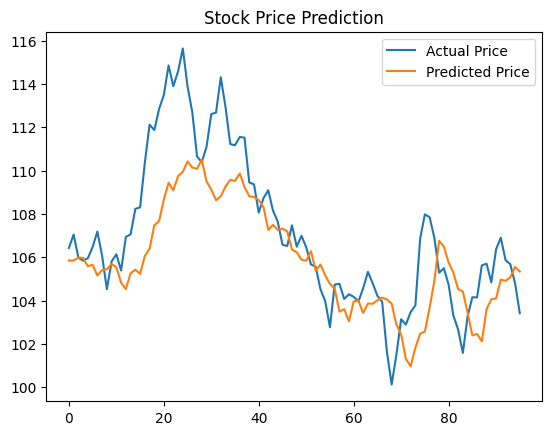

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)

data = 100 + np.cumsum(np.random.randn(500))

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X = []
y = []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    SimpleRNN(32, input_shape=(20, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=10, batch_size=16)

predictions = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(predictions)

print("MAE:", mean_absolute_error(actual, predicted))
print("MSE:", mean_squared_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

plt.plot(actual, label="Actual Price")
plt.plot(predicted, label="Predicted Price")
plt.title("Stock Price Prediction")
plt.legend()
plt.show()

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0753
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0138
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0088
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0071
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0069
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0066
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0070
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0069
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0064
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0062
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Mean Absolute Error: 5.853867146110854


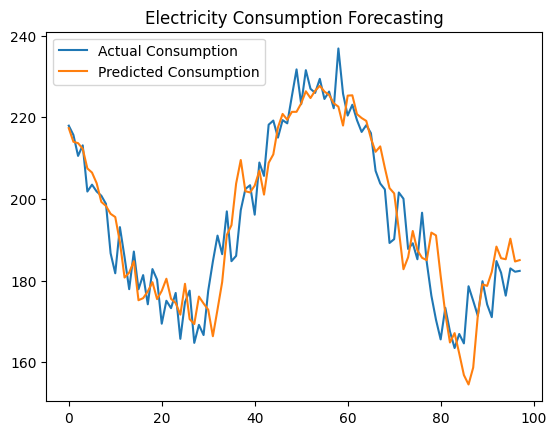

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

data = 200 + 30 * np.sin(np.arange(500) * 0.1)
data += np.random.normal(0, 5, 500)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    SimpleRNN(32, input_shape=(10, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=10, batch_size=16)

predictions = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(predictions)

print("Mean Absolute Error:", mean_absolute_error(actual, predicted))

plt.plot(actual, label="Actual Consumption")
plt.plot(predicted, label="Predicted Consumption")
plt.title("Electricity Consumption Forecasting")
plt.legend()
plt.show()

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

sentences = [
    "deep learning is useful",
    "deep learning is powerful",
    "machine learning is interesting",
    "machine learning helps people",
    "recurrent networks learn patterns",
    "recurrent networks process sequences"
]

tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)

sequences = []

for sentence in sentences:
    tokens = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(1, len(tokens)):
        sequences.append(tokens[:i+1])

max_length = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_length)

X = sequences[:, :-1]
y = sequences[:, -1]

vocab_size = len(tokenizer.word_index) + 1

model = Sequential([
    Embedding(vocab_size, 16),
    SimpleRNN(32),
    Dense(vocab_size, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=1)

loss, accuracy = model.evaluate(X, y, verbose=0)
print("Accuracy:", accuracy)

input_text = "deep learning"
tokens = tokenizer.texts_to_sequences([input_text])[0]
tokens = pad_sequences([tokens], maxlen=max_length-1)

prediction = model.predict(tokens, verbose=0)
next_word = tokenizer.index_word[np.argmax(prediction)]

print("Input:", input_text)
print("Predicted next word:", next_word)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.8081
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.0000e+00 - loss: 2.7935
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.0000e+00 - loss: 2.7795
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.0000e+00 - loss: 2.7658
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.0000e+00 - loss: 2.7525
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3889 - loss: 2.7394
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.2778 - loss: 2.7265
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2778 - loss: 2.7135
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.3333 - loss: 2.7006
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3333 - loss: 2.6875
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5556 - loss: 2.6742
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - acc

In [6]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

np.random.seed(42)

data = 50 + 10*np.sin(np.arange(500)*0.1)
data += np.random.normal(0, 2, 500)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

rnn_model = Sequential([
    SimpleRNN(32, input_shape=(10, 1)),
    Dense(1)
])

rnn_model.compile(optimizer='adam', loss='mse')
rnn_model.fit(X_train, y_train, epochs=10, verbose=1)

rnn_pred = rnn_model.predict(X_test)

lstm_model = Sequential([
    LSTM(32, input_shape=(10, 1)),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_train, y_train, epochs=10, verbose=1)

lstm_pred = lstm_model.predict(X_test)

print("RNN MAE:", mean_absolute_error(y_test, rnn_pred))
print("LSTM MAE:", mean_absolute_error(y_test, lstm_pred))

print("RNN MSE:", mean_squared_error(y_test, rnn_pred))
print("LSTM MSE:", mean_squared_error(y_test, lstm_pred))

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0466
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0171 
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0117 
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0087 
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0078 
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0074
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0072 
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0069 
Epoch 9/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0074 
Epoch 10/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0072 
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1402
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0283
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0215
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0180
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0168
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0160
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0153
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0149
Epoch 9/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0144
Epoch 10/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0142
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
RNN MAE: 0.0725243781115286
LSTM MAE: 0.09629911449434148
RNN MSE: 0.009138743104741966
LSTM MSE: 0.013831337237267313


Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0385
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0071
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0045
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0041
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0039
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0038
Epoch 7/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0035
Epoch 8/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0033
Epoch 9/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0032
Epoch 10/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0031
Epoch 11/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0029
Epoch 12/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0028
Epoch 13/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0028
Epoch 14/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0026
Epoch 15/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0026
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23

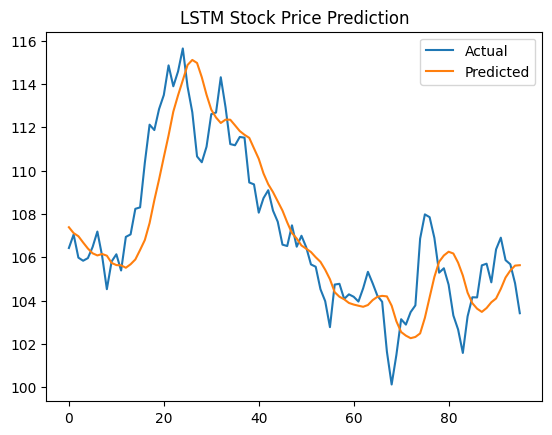

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)

data = 100 + np.cumsum(np.random.randn(500))

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X = []
y = []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    LSTM(50, input_shape=(20, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=15, batch_size=16)

predictions = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(predictions)

print("MAE:", mean_absolute_error(actual, predicted))
print("MSE:", mean_squared_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

plt.plot(actual, label="Actual")
plt.plot(predicted, label="Predicted")
plt.title("LSTM Stock Price Prediction")
plt.legend()
plt.show()

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1348
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0513
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0306
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0167
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0101
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0084
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0074
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0064
Epoch 9/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0057
Epoch 10/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0050
Epoch 11/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0043
Epoch 12/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0037
Epoch 13/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0031
Epoch 14/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0026
Epoch 15/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0021
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6

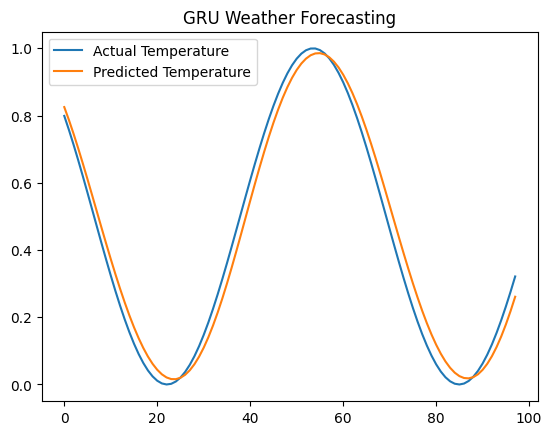

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

data = np.column_stack([
    25 + 5*np.sin(np.arange(500)*0.1),
    60 + 10*np.sin(np.arange(500)*0.08),
    1010 + 5*np.sin(np.arange(500)*0.05)
])

scaler = MinMaxScaler()
data = scaler.fit_transform(data)

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i, 0])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    GRU(32, input_shape=(10, 3)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=15, verbose=1)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))

plt.plot(y_test, label="Actual Temperature")
plt.plot(predictions, label="Predicted Temperature")
plt.title("GRU Weather Forecasting")
plt.legend()
plt.show()

In [9]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

data = np.sin(np.arange(500)*0.1) + 0.3*np.sin(np.arange(500)*0.03)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

models_list = {
    "RNN": SimpleRNN(32, input_shape=(10, 1)),
    "LSTM": LSTM(32, input_shape=(10, 1)),
    "GRU": GRU(32, input_shape=(10, 1))
}

for name, layer in models_list.items():
    model = Sequential([layer, Dense(1)])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X_train, y_train, epochs=10, verbose=0)

    predictions = model.predict(X_test, verbose=0)

    print(name)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("MSE:", mean_squared_error(y_test, predictions))
    print("--------------------")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RNN
MAE: 0.01917558831745179
MSE: 0.0005646960969210909
--------------------
LSTM
MAE: 0.0949778148908414
MSE: 0.011203845021163419
--------------------
GRU
MAE: 0.06614597363149621
MSE: 0.005377057843902999
--------------------


Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1578
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0452
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0284
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0174
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0084
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0046
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0027
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0017
Epoch 9/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0011
Epoch 10/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.9159e-04
Epoch 11/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5.9398e-04
Epoch 12/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.1184e-04
Epoch 13/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4.0829e-04
Epoch 14/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.4906e-04
Epoch 15/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.2025e-04
4/4 ━━

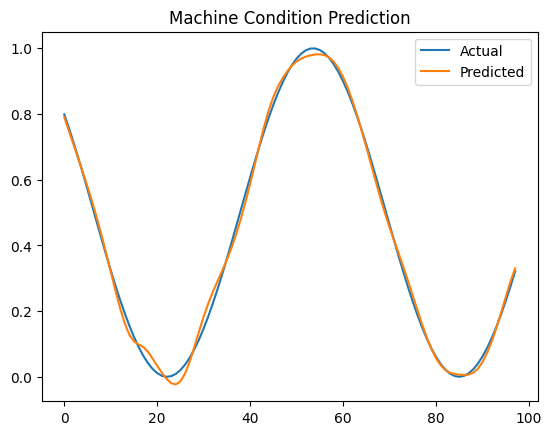

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.preprocessing import MinMaxScaler

data = np.column_stack([
    60 + 5*np.sin(np.arange(500)*0.1),
    30 + 3*np.sin(np.arange(500)*0.2),
    10 + 2*np.sin(np.arange(500)*0.15)
])

scaler = MinMaxScaler()
data = scaler.fit_transform(data)

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i, 0])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    SimpleRNN(32, return_sequences=True, input_shape=(10, 3)),
    SimpleRNN(16),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=15, verbose=1)

predictions = model.predict(X_test)

plt.plot(y_test, label="Actual")
plt.plot(predictions, label="Predicted")
plt.title("Machine Condition Prediction")
plt.legend()
plt.show()

Gradient values:
Time Step 1 : 0.5
Time Step 2 : 0.25
Time Step 3 : 0.125
Time Step 4 : 0.0625
Time Step 5 : 0.03125
Time Step 6 : 0.015625
Time Step 7 : 0.0078125
Time Step 8 : 0.00390625
Time Step 9 : 0.001953125
Time Step 10 : 0.0009765625
Time Step 11 : 0.00048828125
Time Step 12 : 0.000244140625
Time Step 13 : 0.0001220703125
Time Step 14 : 6.103515625e-05
Time Step 15 : 3.0517578125e-05
Time Step 16 : 1.52587890625e-05
Time Step 17 : 7.62939453125e-06
Time Step 18 : 3.814697265625e-06
Time Step 19 : 1.9073486328125e-06
Time Step 20 : 9.5367431640625e-07
Time Step 21 : 4.76837158203125e-07
Time Step 22 : 2.384185791015625e-07
Time Step 23 : 1.1920928955078125e-07
Time Step 24 : 5.960464477539063e-08
Time Step 25 : 2.9802322387695312e-08
Time Step 26 : 1.4901161193847656e-08
Time Step 27 : 7.450580596923828e-09
Time Step 28 : 3.725290298461914e-09
Time Step 29 : 1.862645149230957e-09
Time Step 30 : 9.313225746154785e-10


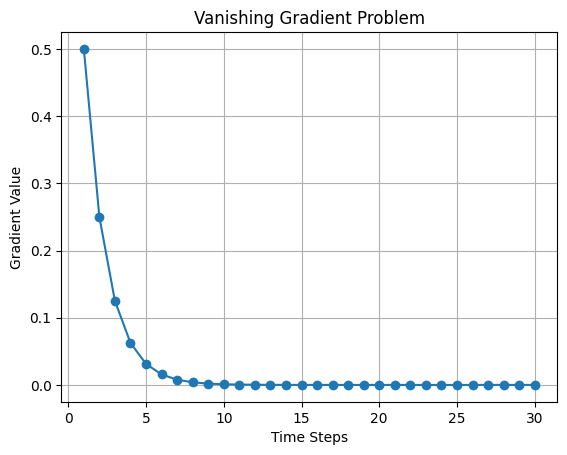

In [11]:
import numpy as np
import matplotlib.pyplot as plt

gradient = 1.0
gradients = []

for i in range(30):
    gradient = gradient * 0.5
    gradients.append(gradient)

print("Gradient values:")

for i, value in enumerate(gradients):
    print("Time Step", i+1, ":", value)

plt.plot(range(1, 31), gradients, marker='o')
plt.xlabel("Time Steps")
plt.ylabel("Gradient Value")
plt.title("Vanishing Gradient Problem")
plt.grid()
plt.show()

In [12]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

data = np.sin(np.arange(500)*0.1)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

for sequence_length in [5, 10, 20]:

    X = []
    y = []

    for i in range(sequence_length, len(data)):
        X.append(data[i-sequence_length:i])
        y.append(data[i])

    X = np.array(X)
    y = np.array(y)

    split = int(0.8*len(X))

    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    model = Sequential([
        SimpleRNN(32, input_shape=(sequence_length, 1)),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')
    model.fit(X_train, y_train, epochs=10, verbose=0)

    predictions = model.predict(X_test, verbose=0)

    error = mean_squared_error(y_test, predictions)

    print("Sequence Length:", sequence_length)
    print("MSE:", error)
    print("----------------------")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 5
MSE: 0.008297100630973858
----------------------


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 10
MSE: 7.217656527186252e-05
----------------------


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 20
MSE: 0.00011192154315243145
----------------------


In [13]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

data = np.sin(np.arange(400)*0.1)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

for learning_rate in [0.001, 0.01]:
    for units in [16, 32]:
        for batch_size in [16, 32]:

            model = Sequential([
                LSTM(units, input_shape=(10, 1)),
                Dense(1)
            ])

            optimizer = tf.keras.optimizers.Adam(
                learning_rate=learning_rate
            )

            model.compile(optimizer=optimizer, loss='mse')

            model.fit(
                X_train, y_train,
                epochs=5,
                batch_size=batch_size,
                verbose=0
            )

            loss = model.evaluate(X_test, y_test, verbose=0)

            print("Learning Rate:", learning_rate)
            print("Hidden Units:", units)
            print("Batch Size:", batch_size)
            print("Test Loss:", loss)
            print("--------------------")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Learning Rate: 0.001
Hidden Units: 16
Batch Size: 16
Test Loss: 0.02959904633462429
--------------------
Learning Rate: 0.001
Hidden Units: 16
Batch Size: 32
Test Loss: 0.020135048776865005
--------------------
Learning Rate: 0.001
Hidden Units: 32
Batch Size: 16
Test Loss: 0.023807385936379433
--------------------
Learning Rate: 0.001
Hidden Units: 32
Batch Size: 32
Test Loss: 0.03997407108545303
--------------------
Learning Rate: 0.01
Hidden Units: 16
Batch Size: 16
Test Loss: 0.000351722032064572
--------------------
Learning Rate: 0.01
Hidden Units: 16
Batch Size: 32
Test Loss: 0.003427660558372736
--------------------
Learning Rate: 0.01
Hidden Units: 32
Batch Size: 16
Test Loss: 1.975431223399937e-05
--------------------
Learning Rate: 0.01
Hidden Units: 32
Batch Size: 32
Test Loss: 0.004449841566383839
--------------------


In [14]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.metrics import mean_absolute_error, mean_squared_error

data = np.sin(np.arange(400)*0.1)

X = []
y = []

for i in range(10, len(data)):
    X.append(data[i-10:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8*len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train = X_train.reshape(-1, 10, 1)
X_test = X_test.reshape(-1, 10, 1)

model = Sequential([
    SimpleRNN(32, input_shape=(10, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=10, verbose=1)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0697
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0109 
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0099 
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0051 
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0047 
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0029 
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022 
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0016 
Epoch 9/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0013 
Epoch 10/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0011     
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Mean Absolute Error: 0.0266396733256198
Mean Squared Error: 0.0010076568204051047
Root Mean Squared Error: 0.03174361070207837


In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, TextVectorization
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

messages = [
    "payment failed", "money deducted payment failed",
    "unable to make payment", "wrong amount charged",
    "product not delivered", "delivery is late",
    "package not received", "order delivery delayed",
    "damaged product received", "product is broken",
    "item quality is poor", "received defective item"
]

labels = np.array([0,0,0,0,1,1,1,1,2,2,2,2])

vectorizer = TextVectorization(
    max_tokens=1000,
    output_sequence_length=8
)

vectorizer.adapt(messages)
X = vectorizer(np.array(messages))

model = Sequential([
    Embedding(1000, 16, mask_zero=True),
    SimpleRNN(32),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X, labels, epochs=30, verbose=1)

predictions = np.argmax(model.predict(X), axis=1)

print("Precision:", precision_score(labels, predictions, average='weighted', zero_division=0))
print("Recall:", recall_score(labels, predictions, average='weighted', zero_division=0))
print("F1 Score:", f1_score(labels, predictions, average='weighted', zero_division=0))

print(classification_report(labels, predictions, zero_division=0))

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0833 - loss: 1.1373
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.0833 - loss: 1.1234
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.1667 - loss: 1.1099
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.2500 - loss: 1.0967
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.4167 - loss: 1.0837
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5833 - loss: 1.0708
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6667 - loss: 1.0580
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.7500 - loss: 1.0453
Epoch 9/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8333 - loss: 1.0325
Epoch 10/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9167 - loss: 1.0196
Epoch 11/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9167 - loss: 1.0066
Epoch 12/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 1.0000 - loss: 0.9933
Epo

In [16]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, Dense, Add, GlobalAveragePooling1D
from tensorflow.keras.models import Model

sentences = [
    "this movie is good",
    "this movie is excellent",
    "the film is wonderful",
    "this movie is bad",
    "the film is terrible",
    "this movie is boring"
]

labels = np.array([1, 1, 1, 0, 0, 0])

tokenizer = tf.keras.preprocessing.text.Tokenizer()
tokenizer.fit_on_texts(sentences)

sequences = tokenizer.texts_to_sequences(sentences)
X = tf.keras.preprocessing.sequence.pad_sequences(sequences, padding='post')

vocab_size = len(tokenizer.word_index) + 1

input_layer = Input(shape=(X.shape[1],))

embedding = Embedding(vocab_size, 16)(input_layer)

left = Dense(16, activation='relu')(embedding)
right = Dense(16, activation='relu')(embedding)

combined = Add()([left, right])

output = GlobalAveragePooling1D()(combined)
output = Dense(1, activation='sigmoid')(output)

model = Model(inputs=input_layer, outputs=output)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X, labels, epochs=30, verbose=1)

predictions = model.predict(X)

for sentence, prediction in zip(sentences, predictions):
    result = "Positive" if prediction[0] > 0.5 else "Negative"
    print(sentence, ":", result)

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.6908
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss: 0.6899
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5000 - loss: 0.6889
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6667 - loss: 0.6880
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6667 - loss: 0.6872
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.6667 - loss: 0.6863
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8333 - loss: 0.6854
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8333 - loss: 0.6846
Epoch 9/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8333 - loss: 0.6837
Epoch 10/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8333 - loss: 0.6828
Epoch 11/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8333 - loss: 0.6819
Epoch 12/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8333 - loss: 0.6809
Epo